# Projet NLP — BERT vs TF-IDF sur SST-2

## 0 — Introduction et configuration

**Phase 1 uniquement : exploration et baseline, sur CPU.**

Nous étudions la classification binaire du sentiment de critiques de films en anglais.
L'objectif général est de comparer une représentation lexicale TF-IDF suivie d'une
régression logistique à BERT, un encodeur Transformer préentraîné qui produit des
représentations contextuelles. La baseline apprend ici ses poids uniquement à partir
du train ; l'approche contextuelle sera développée après validation de cette phase.

Ce notebook couvre les étapes **Explore** et **Baseline** du module 7 du cours
(diapositives « Hands-on » et « Exercise roadmap »). Aucune implémentation de BERT,
de son tokenizer ou du fine-tuning n'est incluse.

**Protocole fixé avant évaluation :** train officiel pour apprendre le vocabulaire,
les IDF et le classifieur ; validation officielle pour mesurer les performances.
Pas de recherche d'hyperparamètres sur la validation. Le split test, dont les labels
ne sont pas publics, ne sert à aucune analyse ni mesure. Les futurs modèles devront
être évalués sur les mêmes 872 exemples de validation. Cette validation n'est pas
un test final indépendant, en particulier si elle guide ensuite le choix des modèles.

Exécuter toutes les cellules dans l'ordre. Sur Colab, choisir **CPU**, puis
**Exécution → Tout exécuter**. Une connexion Internet est nécessaire pour installer
les bibliothèques et télécharger SST-2 lors du premier lancement.


### Dépendances

La cellule suivante reprend les bornes de `requirements.txt` et fonctionne aussi
quand le notebook est importé seul dans Colab. Python **3.11 à 3.13** est recommandé.
Les versions réellement utilisées seront affichées et enregistrées dans le JSON.
PyTorch et Transformers ne sont pas nécessaires à cette phase.

Si Colab demande un redémarrage après une installation, redémarrer la session et
relancer toutes les cellules. Les bornes évitent les nouvelles versions majeures de
pandas/datasets et les changements d'API de scikit-learn à partir de 1.8.


In [14]:
%pip install -q "numpy>=1.26,<3" "pandas>=2.2,<3" "scikit-learn>=1.5,<1.8" "matplotlib>=3.9,<3.11" "datasets>=3,<5" "ipython>=8,<10"


In [15]:
import importlib.metadata
import importlib.util
import json
import os
from pathlib import Path
import platform
import random
import sys
from time import perf_counter
import warnings
from zipfile import ZipFile

# Depuis notebooks/, les exports vont dans ../results/ ; dans Colab, dans ./results/.
working_dir = Path.cwd().resolve()
PROJECT_ROOT = working_dir.parent if working_dir.name == "notebooks" else working_dir
RESULTS_DIR = PROJECT_ROOT / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("HF_HOME", str(PROJECT_ROOT / ".cache" / "huggingface"))
os.environ.setdefault("MPLCONFIGDIR", str(PROJECT_ROOT / ".cache" / "matplotlib"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from datasets import load_dataset
from IPython.display import display, Markdown
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay,
)
from sklearn.pipeline import Pipeline

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
LABEL_NAMES = {0: "négatif", 1: "positif"}
IN_COLAB = importlib.util.find_spec("google.colab") is not None if importlib.util.find_spec("google") else False
VERSIONS = {
    name: importlib.metadata.version(name)
    for name in ("numpy", "pandas", "scikit-learn", "matplotlib", "datasets", "ipython")
}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": False, "font.size": 11})
pd.set_option("display.max_colwidth", 160)

print(f"Environnement : {'Google Colab' if IN_COLAB else 'Jupyter / local'}")
print(f"Python : {sys.version.split()[0]} | système : {platform.system()}")
print(f"Calcul : CPU | seed : {SEED} | dossier des résultats : {RESULTS_DIR}")
display(pd.Series(VERSIONS, name="version").to_frame())


Environnement : Google Colab
Python : 3.13.16 | système : Linux
Calcul : CPU | seed : 42 | dossier des résultats : /content/results


,version
numpy,2.4.6
pandas,2.2.3
scikit-learn,1.6.1
matplotlib,3.10.0
datasets,4.8.5
ipython,9.18.1


## 1 — Exploration SST-2

[SST-2 dans GLUE](https://huggingface.co/datasets/nyu-mll/glue) contient des textes
issus du Stanford Sentiment Treebank, avec **0 = négatif** et **1 = positif**.
Le train comprend aussi des fragments annotés ; il ne faut donc pas supposer que
ses longueurs suivent exactement la distribution des phrases de validation.

Le chargement ci-dessous récupère la configuration SST-2 officielle. Seuls les
splits `train` et `validation` sont ensuite consultés. Nous vérifions leurs tailles,
les labels et la présence de textes exploitables avant tout entraînement.


In [16]:
dataset = load_dataset("nyu-mll/glue", "sst2")
train_df = dataset["train"].to_pandas()
validation_df = dataset["validation"].to_pandas()
frames = {"train": train_df, "validation": validation_df}

assert len(train_df) == 67_349, "Taille inattendue du split train."
assert len(validation_df) == 872, "Taille inattendue du split validation."
for split_name, frame in frames.items():
    assert {"sentence", "label", "idx"}.issubset(frame.columns), split_name
    assert frame["sentence"].notna().all(), split_name
    assert frame["sentence"].str.strip().str.len().gt(0).all(), split_name
    assert set(frame["label"].unique()) == {0, 1}, split_name
    assert frame["idx"].is_unique, split_name

dimensions = pd.DataFrame([
    {"split": name, "exemples": len(frame), "colonnes_source": frame.shape[1]}
    for name, frame in frames.items()
]).set_index("split")
display(dimensions)
print("Colonnes source :", list(train_df.columns))

# Exemples équilibrés pour illustrer les deux annotations, sans entraîner de modèle.
examples = pd.concat([
    train_df.loc[train_df["label"].eq(label)].sample(n=3, random_state=SEED)
    for label in (0, 1)
]).copy()
examples["sentiment"] = examples["label"].map(LABEL_NAMES)
display(examples[["sentence", "label", "sentiment"]].reset_index(drop=True))


Using the latest cached version of the dataset since nyu-mll/glue couldn't be found on the Hugging Face Hub
Found the latest cached dataset configuration 'sst2' at /content/.cache/huggingface/datasets/nyu-mll___glue/sst2/0.0.0/bcdcba79d07bc864c1c254ccfcedcce55bcc9a8c (last modified on Sun Nov 22 18:26:17 2026).


,exemples,colonnes_source
split,,
train,67349,3
validation,872,3


Colonnes source : ['sentence', 'label', 'idx']


,sentence,label,sentiment
0,"a dull , dumb and derivative horror",0,négatif
1,"if george romero had directed this movie , it would n't have taken the protagonists a full hour to determine that in order to kill a zombie you must shoot i...",0,négatif
2,"the acting is amateurish , the cinematography is atrocious",0,négatif
3,"acted meditation on both the profoundly devastating events of one year ago and the slow , painful healing process that has followed in their wake",1,positif
4,"this odd , poetic road movie , spiked by jolts of pop music , pretty much takes place in morton 's ever-watchful gaze -- and it 's a tribute to the actress ...",1,positif
5,"directed with purpose and finesse by england 's roger mitchell , who handily makes the move from pleasing , relatively lightweight commercial fare such as n...",1,positif


,négatif,positif
split,,
train,29780,37569
validation,428,444


,négatif (%),positif (%)
split,,
train,44.22,55.78
validation,49.08,50.92


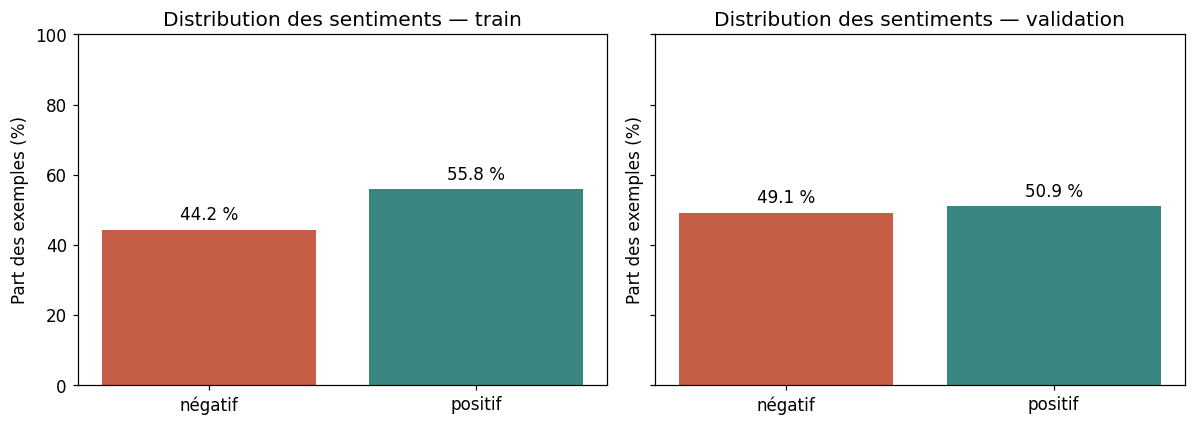

Le sentiment positif représente **55.8 %** du train et **50.9 %** de la validation. Ces proportions donnent le contexte de l'accuracy ; précision, rappel et F1 complètent l'évaluation de la classe positive. Aucun rééquilibrage n'est appliqué.

In [17]:
class_counts = pd.DataFrame({
    name: frame["label"].value_counts().reindex([0, 1], fill_value=0)
    for name, frame in frames.items()
}).T
class_counts.columns = [LABEL_NAMES[0], LABEL_NAMES[1]]
class_percentages = class_counts.div(class_counts.sum(axis=1), axis=0).mul(100)
display(class_counts.rename_axis("split"))
display(class_percentages.round(2).rename_axis("split").add_suffix(" (%)"))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, name in zip(axes, frames):
    values = class_percentages.loc[name]
    bars = ax.bar(values.index, values.values, color=["#C65D46", "#378780"])
    ax.bar_label(bars, labels=[f"{value:.1f} %" for value in values], padding=4)
    ax.set(title=f"Distribution des sentiments — {name}", ylim=(0, 100), ylabel="Part des exemples (%)")
fig.tight_layout()
plt.show()

display(Markdown(
    f"Le sentiment positif représente **{class_percentages.loc['train', 'positif']:.1f} %** du train "
    f"et **{class_percentages.loc['validation', 'positif']:.1f} %** de la validation. "
    "Ces proportions donnent le contexte de l'accuracy ; précision, rappel et F1 "
    "complètent l'évaluation de la classe positive. Aucun rééquilibrage n'est appliqué."
))


### Longueur des textes et contrôle des recouvrements

Le nombre de **mots** est estimé par une séparation sur les espaces, ponctuation
comprise ; le nombre de **caractères** inclut les espaces. Il s'agit de mesures
descriptives, distinctes des unités que retient `TfidfVectorizer`.

Le contrôle des doublons ci-dessous recherche les textes identiques après passage
en minuscules et normalisation des espaces. Il ne détecte pas tous les fragments
qui se recouvrent ni les paraphrases. Les splits officiels sont conservés pour la
comparabilité : un éventuel recouvrement provenant du corpus sera signalé, sans
suppression silencieuse d'exemples. Le vocabulaire et les IDF restent appris sur le
train uniquement, indépendamment de ces observations descriptives.


count    mean    std  min    50%    90%     95%  \
split      mesure                                                            
train      n_words       67349.0    9.41   8.07  1.0    7.0   21.0   26.00   
           n_characters  67349.0   53.51  43.41  2.0   39.0  117.0  145.00   
validation n_words         872.0   19.55   8.76  2.0   19.0   31.9   34.45   
           n_characters    872.0  105.84  48.13  6.0  103.0  171.0  186.45   

                            99%    max  
split      mesure                       
train      n_words        35.00   52.0  
           n_characters  194.00  268.0  
validation n_words        42.00   47.0  
           n_characters  222.29  244.0

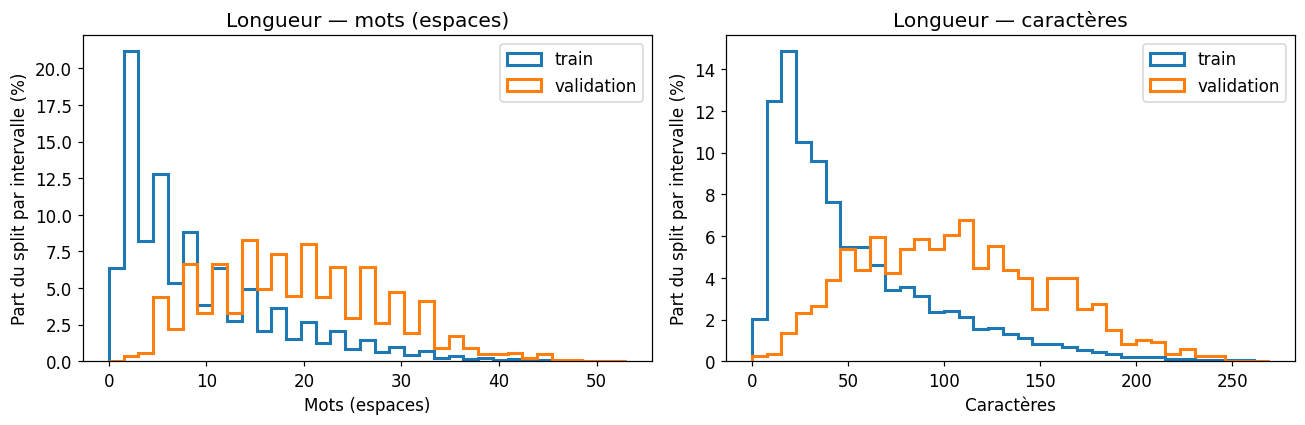

La longueur médiane est de **7 mots** dans le train et **19 mots** dans la validation. La présence de fragments dans le train peut contribuer à cet écart ; ces statistiques ne suffisent pas à en établir toutes les causes. La baseline conserve les textes entiers, sans troncature.

Doublons internes normalisés : {'train': 371, 'validation': 0}
Textes normalisés communs aux splits : 0
Lignes de validation concernées : 0
Aucun texte entier identique détecté avec cette normalisation.


In [18]:
for frame in frames.values():
    frame["n_words"] = frame["sentence"].str.split().str.len()
    frame["n_characters"] = frame["sentence"].str.len()

length_stats = pd.concat({
    name: frame[["n_words", "n_characters"]].describe(percentiles=[0.5, 0.9, 0.95, 0.99]).T
    for name, frame in frames.items()
}, names=["split", "mesure"])
display(length_stats.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, column, label in zip(axes, ["n_words", "n_characters"], ["Mots (espaces)", "Caractères"]):
    maximum = max(frame[column].max() for frame in frames.values())
    bins = np.linspace(0, maximum + 1, 36)
    for name, frame in frames.items():
        # Pondération en pourcentage pour comparer des splits de tailles différentes.
        ax.hist(frame[column], bins=bins, weights=np.full(len(frame), 100 / len(frame)),
                histtype="step", linewidth=2, label=name)
    ax.set(xlabel=label, ylabel="Part du split par intervalle (%)", title=f"Longueur — {label.lower()}")
    ax.legend()
fig.tight_layout()
plt.show()

train_median = train_df["n_words"].median()
validation_median = validation_df["n_words"].median()
display(Markdown(
    f"La longueur médiane est de **{train_median:.0f} mots** dans le train et "
    f"**{validation_median:.0f} mots** dans la validation. "
    "La présence de fragments dans le train peut contribuer à cet écart ; "
    "ces statistiques ne suffisent pas à en établir toutes les causes. "
    "La baseline conserve les textes entiers, sans troncature."
))

normalized_texts = {
    name: frame["sentence"].str.lower().str.split().str.join(" ")
    for name, frame in frames.items()
}
overlap_texts = set(normalized_texts["train"]) & set(normalized_texts["validation"])
overlap_validation_rows = int(normalized_texts["validation"].isin(overlap_texts).sum())
print("Doublons internes normalisés :", {
    name: int(texts.duplicated().sum()) for name, texts in normalized_texts.items()
})
print(f"Textes normalisés communs aux splits : {len(overlap_texts)}")
print(f"Lignes de validation concernées : {overlap_validation_rows}")
if overlap_texts:
    display(Markdown(
        "**Limite du corpus :** des textes identiques sont présents dans les deux splits. "
        "L'évaluation conserve le protocole officiel ; cette dépendance doit être "
        "mentionnée lors de l'interprétation des scores."
    ))
else:
    print("Aucun texte entier identique détecté avec cette normalisation.")


## 2 — Baseline TF-IDF + régression logistique

Les hyperparamètres suivants sont fixés **sans optimisation sur la validation**.

| Élément | Paramètres et motivation |
| --- | --- |
| TF-IDF | `ngram_range=(1, 2)` : mots et paires de mots pour des indices locaux tels que « not good ». |
| Vocabulaire | `min_df=2`, `max_df=1.0`, `max_features=100000` : écarter les termes présents dans un seul document et limiter la mémoire. |
| Pondération | `sublinear_tf=True`, `use_idf=True`, `smooth_idf=True`, `norm='l2'` : fréquence logarithmique et normalisation par document. |
| Texte | Minuscules ; ni stopwords ni lemmatisation pour conserver notamment les négations. Le motif standard retient les suites d'au moins deux caractères de mot et sépare aux ponctuations. |
| Classifieur | `C=1.0`, pénalité L2, `solver='lbfgs'`, `max_iter=1000`, `tol=1e-4`, `class_weight=None`, `random_state=42`. |

`Pipeline.fit` reçoit exclusivement les 67 349 textes et labels du train.
`Pipeline.predict` transforme la validation avec le vocabulaire et les IDF déjà
appris. Aucune matrice dense n'est créée. Un défaut de convergence interrompt
l'exécution pour éviter d'exporter discrètement une baseline non convergée.

La seed fixe les tirages d'exemples et les composants qui utilisent un générateur
aléatoire. De petites variations numériques restent possibles selon les versions
des bibliothèques et les bibliothèques de calcul du système.


In [19]:
X_train = train_df["sentence"].tolist()
y_train = train_df["label"].to_numpy(dtype=np.int64)
X_validation = validation_df["sentence"].tolist()
y_validation = validation_df["label"].to_numpy(dtype=np.int64)

TFIDF_PARAMS = {
    "ngram_range": (1, 2),
    "min_df": 2,
    "max_df": 1.0,
    "max_features": 100_000,
    "lowercase": True,
    "stop_words": None,
    "sublinear_tf": True,
    "use_idf": True,
    "smooth_idf": True,
    "norm": "l2",
}
LOGREG_PARAMS = {
    "C": 1.0,
    "penalty": "l2",
    "solver": "lbfgs",
    "max_iter": 1000,
    "tol": 1e-4,
    "class_weight": None,
    "random_state": SEED,
}
baseline = Pipeline([
    ("tfidf", TfidfVectorizer(**TFIDF_PARAMS)),
    ("logreg", LogisticRegression(**LOGREG_PARAMS)),
])

training_start = perf_counter()
with warnings.catch_warnings():
    warnings.simplefilter("error", ConvergenceWarning)
    baseline.fit(X_train, y_train)
training_seconds = perf_counter() - training_start
y_pred = baseline.predict(X_validation)

assert len(y_pred) == 872
assert set(np.unique(y_pred)).issubset({0, 1})
print(f"Entraînement CPU : {training_seconds:.2f} s")
print(f"Vocabulaire appris sur train : {len(baseline.named_steps['tfidf'].vocabulary_):,} caractéristiques")
print("Itérations du classifieur :", baseline.named_steps["logreg"].n_iter_.tolist())


Entraînement CPU : 3.62 s
Vocabulaire appris sur train : 74,055 caractéristiques
Itérations du classifieur : [49]


### Mesures sur la validation et analyse des erreurs

L'accuracy est la proportion totale de bonnes prédictions. Les trois métriques
binaires utilisent **1 (positif)** : la précision mesure la part de vrais positifs
parmi les prédictions positives ; le rappel mesure la part de positifs retrouvés ;
F1 est leur moyenne harmonique. Les scores sont exportés entre 0 et 1.
`zero_division=0` fixe explicitement le comportement si un dénominateur est nul.


,accuracy,precision,recall,f1
TF-IDF + régression logistique,0.805,0.7831,0.8536,0.8168


Erreurs : 170 / 872


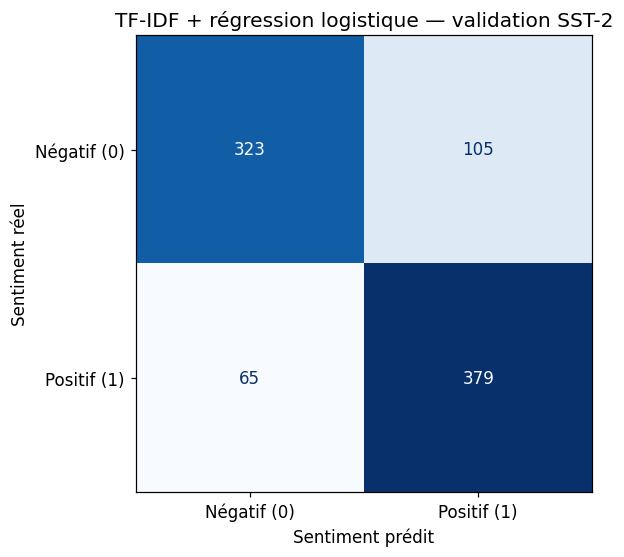

,idx,sentence,true_label,predicted_label,sentiment_reel,sentiment_predit
0,728,"but taken as a stylish and energetic one-shot , the queen of the damned can not be said to suck .",1,0,positif,négatif
1,133,"the tale of tok ( andy lau ) , a sleek sociopath on the trail of o ( takashi sorimachi ) , the most legendary of asian hitmen , is too scattershot to take h...",0,1,négatif,positif
2,631,burns never really harnesses to full effect the energetic cast .,0,1,négatif,positif
3,124,"( lawrence bounces ) all over the stage , dancing , running , sweating , mopping his face and generally displaying the wacky talent that brought him fame in...",1,0,positif,négatif
4,749,a working class `` us vs. them '' opera that leaves no heartstring untugged and no liberal cause unplundered .,1,0,positif,négatif
5,847,"... mafia , rap stars and hood rats butt their ugly heads in a regurgitation of cinematic violence that gives brutal birth to an unlikely , but likable , he...",1,0,positif,négatif
6,856,"in a way , the film feels like a breath of fresh air , but only to those that allow it in .",1,0,positif,négatif
7,248,"a full world has been presented onscreen , not some series of carefully structured plot points building to a pat resolution .",1,0,positif,négatif
8,575,"( director ) o'fallon manages to put some lovely pictures up on the big screen , but his skill at telling a story -- he also contributed to the screenplay -...",0,1,négatif,positif
9,296,its well of thorn and vinegar ( and simple humanity ) has long been plundered by similar works featuring the insight and punch this picture so conspicuously...,0,1,négatif,positif


La baseline atteint **80.50% d'accuracy** et un **F1 positif de 0.8168**, avec **170 erreurs**. La matrice compte **105 faux positifs** et **65 faux négatifs**. Les exemples affichés permettent d'examiner des hypothèses comme la négation, les opinions mixtes ou l'ironie ; ces causes doivent être vérifiées en lisant chaque phrase. Ces résultats constituent le point de départ de la future comparaison.

In [20]:
def compute_binary_metrics(y_true, predictions):
    """Évaluer des labels binaires alignés ; la classe positive est toujours 1."""
    y_true = np.asarray(y_true)
    predictions = np.asarray(predictions)
    if y_true.ndim != 1 or y_true.shape != predictions.shape or y_true.size == 0:
        raise ValueError("Les labels et prédictions doivent être des vecteurs non vides de même taille.")
    if not np.isin(y_true, [0, 1]).all() or not np.isin(predictions, [0, 1]).all():
        raise ValueError("Seuls les labels binaires 0 et 1 sont acceptés.")
    return {
        "accuracy": float(accuracy_score(y_true, predictions)),
        "precision": float(precision_score(y_true, predictions, pos_label=1, zero_division=0)),
        "recall": float(recall_score(y_true, predictions, pos_label=1, zero_division=0)),
        "f1": float(f1_score(y_true, predictions, pos_label=1, zero_division=0)),
    }


metrics = compute_binary_metrics(y_validation, y_pred)
cm = confusion_matrix(y_validation, y_pred, labels=[0, 1])
n_errors = int(np.count_nonzero(y_validation != y_pred))
assert int(cm.sum()) == len(y_validation)
assert int(cm.sum() - np.trace(cm)) == n_errors
display(pd.DataFrame([metrics], index=["TF-IDF + régression logistique"]).round(4))
print(f"Erreurs : {n_errors} / {len(y_validation)}")

fig_cm, ax_cm = plt.subplots(figsize=(6.4, 5.2))
ConfusionMatrixDisplay(cm, display_labels=["Négatif (0)", "Positif (1)"]).plot(
    ax=ax_cm, cmap="Blues", values_format="d", colorbar=False
)
ax_cm.set(title="TF-IDF + régression logistique — validation SST-2",
          xlabel="Sentiment prédit", ylabel="Sentiment réel")
fig_cm.tight_layout()
plt.show()

predictions_df = pd.DataFrame({
    "idx": validation_df["idx"].to_numpy(),
    "sentence": X_validation,
    "true_label": y_validation,
    "predicted_label": y_pred,
})
errors_df = predictions_df.loc[predictions_df["true_label"] != predictions_df["predicted_label"]].copy()
errors_df["sentiment_reel"] = errors_df["true_label"].map(LABEL_NAMES)
errors_df["sentiment_predit"] = errors_df["predicted_label"].map(LABEL_NAMES)
if len(errors_df):
    display(errors_df.sample(n=min(10, len(errors_df)), random_state=SEED).reset_index(drop=True))
else:
    print("Aucune erreur sur la validation.")

display(Markdown(
    f"La baseline atteint **{metrics['accuracy']:.2%} d'accuracy** et un "
    f"**F1 positif de {metrics['f1']:.4f}**, avec **{n_errors} erreurs**. "
    f"La matrice compte **{int(cm[0, 1])} faux positifs** et **{int(cm[1, 0])} faux négatifs**. "
    "Les exemples affichés permettent d'examiner des hypothèses comme la négation, "
    "les opinions mixtes ou l'ironie ; ces causes doivent être vérifiées en lisant "
    "chaque phrase. Ces résultats constituent le point de départ de la future comparaison."
))


### Sauvegarde des résultats réellement calculés

Les fichiers suivants sont créés uniquement après entraînement et évaluation réussis :

- `results/tfidf_metrics.json` : métriques, erreurs, matrice, protocole, hyperparamètres,
  versions et empreintes des données chargées ;
- `results/tfidf_predictions.csv` : les 872 textes de validation dans leur ordre
  officiel, leur identifiant, leur label réel et leur prédiction ;
- `results/tfidf_confusion_matrix.png` : figure lisible avec axes réel/prédit.

Les empreintes des splits facilitent la traçabilité ; elles ne remplacent pas une
révision figée du dépôt de données. Les bornes de dépendances assurent la compatibilité,
pas une reproduction bit à bit entre machines.


In [21]:
metrics_path = RESULTS_DIR / "tfidf_metrics.json"
predictions_path = RESULTS_DIR / "tfidf_predictions.csv"
confusion_path = RESULTS_DIR / "tfidf_confusion_matrix.png"
metrics_payload = {
    **metrics,
    "model": "tfidf_logistic_regression",
    "seed": SEED,
    "positive_label": 1,
    "n_train": len(train_df),
    "n_validation": len(validation_df),
    "n_errors": n_errors,
    "confusion_matrix": cm.tolist(),
    "confusion_matrix_label_order": [0, 1],
    "training_seconds": training_seconds,
    "vocabulary_size": len(baseline.named_steps["tfidf"].vocabulary_),
    "classifier_iterations": baseline.named_steps["logreg"].n_iter_.tolist(),
    "hyperparameters": {"tfidf": TFIDF_PARAMS, "logistic_regression": LOGREG_PARAMS},
    "dataset": {
        "name": "nyu-mll/glue", "configuration": "sst2",
        "fit_split": "train", "evaluation_split": "validation",
        "train_fingerprint": dataset["train"]._fingerprint,
        "validation_fingerprint": dataset["validation"]._fingerprint,
        "normalized_overlap_texts": len(overlap_texts),
        "normalized_overlap_validation_rows": overlap_validation_rows,
    },
    "environment": {"python": platform.python_version(), "platform": platform.system(), "device": "CPU"},
    "library_versions": VERSIONS,
}
metrics_path.write_text(json.dumps(metrics_payload, indent=2, ensure_ascii=False, allow_nan=False) + "\n", encoding="utf-8")
predictions_df.to_csv(predictions_path, index=False, encoding="utf-8")
fig_cm.savefig(confusion_path, dpi=180, bbox_inches="tight", facecolor="white")
plt.close(fig_cm)

# Vérification des exports : schéma, ordre des exemples et cohérence des métriques.
saved_metrics = json.loads(metrics_path.read_text(encoding="utf-8"))
saved_predictions = pd.read_csv(predictions_path, encoding="utf-8", keep_default_na=False)
assert len(saved_predictions) == 872
assert saved_predictions["sentence"].tolist() == X_validation
assert saved_predictions["idx"].tolist() == validation_df["idx"].tolist()
assert saved_predictions["true_label"].tolist() == y_validation.tolist()
assert saved_predictions["predicted_label"].tolist() == y_pred.tolist()
recomputed_metrics = compute_binary_metrics(saved_predictions["true_label"], saved_predictions["predicted_label"])
for name, value in recomputed_metrics.items():
    assert np.isclose(value, saved_metrics[name]), name
assert confusion_path.read_bytes().startswith(b"\x89PNG\r\n\x1a\n")
for path in (metrics_path, predictions_path, confusion_path):
    print(f"Créé et vérifié : {path.name} ({path.stat().st_size:,} octets)")


Créé et vérifié : tfidf_metrics.json (1,636 octets)
Créé et vérifié : tfidf_predictions.csv (101,040 octets)
Créé et vérifié : tfidf_confusion_matrix.png (48,463 octets)


### Récupération dans Colab et arrêt de la phase 1

La cellule suivante crée une archive des **trois résultats réels**. Dans Colab,
elle lance son téléchargement ; si le navigateur le bloque, récupérer les fichiers
dans le panneau **Fichiers → results**. Télécharger également le notebook exécuté
via **Fichier → Télécharger → Télécharger le fichier .ipynb** pour conserver les sorties.

**À faire valider :** notebook exécuté, JSON des métriques, CSV des prédictions et
PNG de la matrice. Aucun score de BERT n'a été calculé. BERT et le reporting
comparatif sont réservés aux phases suivantes.

**Fin de la phase 1.** Attendre la validation explicite :
« Phase 1 validée, passe à la phase 2. »


In [22]:
archive_path = RESULTS_DIR / "phase1_results.zip"
with ZipFile(archive_path, "w") as archive:
    for path in (metrics_path, predictions_path, confusion_path):
        archive.write(path, arcname=path.name)
print(f"Archive des résultats : {archive_path}")
if IN_COLAB:
    from google.colab import files
    files.download(str(archive_path))


Archive des résultats : /content/results/phase1_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Références

- Support local : `NLP_Course_Module7_Transformer_BERT (1).pptx`, dans le ZIP fourni,
  consulté en lecture seule ; étapes « Explore » et « Baseline ».
- [Fiche officielle GLUE / SST-2](https://huggingface.co/datasets/nyu-mll/glue).
- [TF-IDF dans scikit-learn](https://scikit-learn.org/1.7/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html).
- [Régression logistique dans scikit-learn](https://scikit-learn.org/1.7/modules/generated/sklearn.linear_model.LogisticRegression.html).


## 3 — BERT : tokenisation et validation technique (phase 2)

La phase 1 a été validée et publiée dans le commit
[`ecb4c82`](https://github.com/gueri-jpg/nlp-bert-vs-tfidf-sst2/commit/ecb4c82e3a36fd1c3d3d05b2efaad01e996feb5a).
Les sections 0 à 2, leurs sorties et les trois résultats TF-IDF sont conservés.
Leurs mentions « phase 1 uniquement » décrivent ce premier jalon historique.

**Pour cette phase, démarrer une session neuve et exécuter uniquement les cellules
à partir de cette section 3, dans l'ordre.** Elle possède ses propres imports et
charge SST-2 sans dépendre des variables de la baseline. Ne pas utiliser « Tout
exécuter » sur le notebook entier : les anciennes cellules réentraîneraient la
baseline et réécriraient ses exports. Aucun fichier TF-IDF n'est écrit en section 3.

Le modèle imposé est **`bert-base-uncased`**. Cette phase prépare les données et
effectue, si la mémoire le permet, **deux étapes d'optimisation au maximum** sur
16 exemples de train, puis prédit sur 8 exemples de validation. Ce smoke test est
un contrôle technique, sans valeur de comparaison avec la baseline.
L'entraînement complet et toute comparaison statistique restent réservés à la phase 3.


### 3.0 — Installation, versions, API et ressources

La cellule d'installation reprend les bornes de `requirements.txt`, y compris les
dépendances de base, pour fonctionner depuis une session Colab vide. Elle conserve
une installation PyTorch compatible déjà présente, notamment sa variante CUDA.
Transformers est borné à la branche 4.57 ; les paramètres de `Trainer` et
`TrainingArguments` sont également contrôlés par introspection à l'exécution.

Si une bibliothèque déjà importée est remplacée (en particulier Hugging Face Hub),
redémarrer la session avant de continuer. Sous Colab, choisir un GPU T4 si disponible.
Sans GPU, le code utilise le CPU ; le téléchargement des poids et le smoke test
sont différés si la RAM libre est insuffisante. Le contrôle mémoire est une
estimation prudente, pas une garantie contre un dépassement.


In [23]:
%pip install -q "numpy>=1.26,<3" "pandas>=2.2,<3" "scikit-learn>=1.5,<1.8" "matplotlib>=3.9,<3.11" "datasets>=3,<5" "ipython>=8,<10" "torch>=2.6,<3" "transformers>=4.57,<5" "accelerate>=1.6,<2" "safetensors>=0.4.3,<1" "psutil>=5.9,<8"


In [24]:
import gc
import hashlib
import importlib.metadata
import importlib.util
import inspect
import json
import os
import sys
from pathlib import Path
import platform
from datetime import datetime, timezone
import warnings
import importlib

PHASE2_ROOT = Path.cwd().resolve()
if PHASE2_ROOT.name == "notebooks":
    PHASE2_ROOT = PHASE2_ROOT.parent
PHASE2_RESULTS = PHASE2_ROOT / "results" / "phase2"
PHASE2_RESULTS.mkdir(parents=True, exist_ok=True)
PHASE2_CACHE = PHASE2_ROOT / ".cache"
os.environ.setdefault("HF_HOME", str(PHASE2_CACHE / "huggingface"))
os.environ.setdefault("MPLCONFIGDIR", str(PHASE2_CACHE / "matplotlib"))
os.environ.setdefault("USE_TF", "0")

# Force le rechargement complet de huggingface_hub pour éviter les imports cassés
for key in list(sys.modules.keys()):
    if key == "huggingface_hub" or key.startswith("huggingface_hub."):
        sys.modules.pop(key, None)

import huggingface_hub
importlib.reload(huggingface_hub)

if huggingface_hub.__version__ != importlib.metadata.version("huggingface-hub"):
    warnings.warn(f"Hugging Face Hub version mismatch (memory: {huggingface_hub.__version__} vs metadata: {importlib.metadata.version('huggingface-hub')}). Attempting to proceed.")

import accelerate
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import torch
import transformers
from datasets import DatasetDict, load_dataset
from IPython.display import Markdown, display
from sklearn.metrics import accuracy_score, f1_score
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding,
    Trainer, TrainerCallback, TrainingArguments, set_seed,
)

BERT_MODEL_NAME = "bert-base-uncased"
BERT_SEED = 42
set_seed(BERT_SEED)
HAS_CUDA = torch.cuda.is_available()
BERT_DEVICE = torch.device("cuda" if HAS_CUDA else "cpu")
torch.set_num_threads(min(4, torch.get_num_threads()))
PHASE2_VERSIONS = {
    name: importlib.metadata.version(name)
    for name in ("torch", "transformers", "accelerate", "datasets", "tokenizers", "huggingface-hub", "safetensors", "numpy", "psutil")
}
training_api = inspect.signature(TrainingArguments.__init__).parameters
trainer_api = inspect.signature(Trainer.__init__).parameters
assert {"eval_strategy", "use_cpu", "max_steps", "save_strategy"}.issubset(training_api)
assert {"processing_class", "compute_metrics", "data_collator"}.issubset(trainer_api)
assert callable(getattr(TrainerCallback, "on_pre_optimizer_step", None))


def bert_memory_snapshot():
    snapshot = {
        "ram_available_gib": psutil.virtual_memory().available / 2**30,
        "process_rss_gib": psutil.Process().memory_info().rss / 2**30,
    }
    if HAS_CUDA:
        free, total = torch.cuda.mem_get_info()
        snapshot.update({
            "gpu_free_gib": free / 2**30, "gpu_total_gib": total / 2**30,
            "gpu_allocated_gib": torch.cuda.memory_allocated() / 2**30,
            "gpu_reserved_gib": torch.cuda.memory_reserved() / 2**30,
            "gpu_peak_allocated_gib": torch.cuda.max_memory_allocated() / 2**30,
        })
    return snapshot


BASELINE_FILES = [PHASE2_ROOT / "results" / name for name in
                  ("tfidf_metrics.json", "tfidf_predictions.csv", "tfidf_confusion_matrix.png")]
baseline_hashes_before = {p.name: hashlib.sha256(p.read_bytes()).hexdigest()
                          for p in BASELINE_FILES if p.exists()}
phase2_memory_initial = bert_memory_snapshot()
print("Python :", platform.python_version(), "| calcul :", BERT_DEVICE)
display(pd.Series(PHASE2_VERSIONS, name="version").to_frame())
print("API présentes : eval_strategy, use_cpu, processing_class, on_pre_optimizer_step.")
if HAS_CUDA:
    print("GPU :", torch.cuda.get_device_name(0), "| CUDA PyTorch :", torch.version.cuda)
else:
    print("Aucun GPU CUDA : tokenisation sur CPU ; smoke test CPU seulement si la RAM le permet.")
print("Mémoire initiale :", phase2_memory_initial)

Python : 3.13.16 | calcul : cuda


,version
torch,2.14.1+cu130
transformers,4.57.6
accelerate,1.15.0
datasets,4.8.5
tokenizers,0.22.2
huggingface-hub,0.36.2
safetensors,0.8.0
numpy,2.4.6
psutil,7.2.2


API présentes : eval_strategy, use_cpu, processing_class, on_pre_optimizer_step.
GPU : Tesla T4 | CUDA PyTorch : 13.0
Mémoire initiale : {'ram_available_gib': 10.704849243164062, 'process_rss_gib': 1.376251220703125, 'gpu_free_gib': 14.46075439453125, 'gpu_total_gib': 14.56317138671875, 'gpu_allocated_gib': 0.0, 'gpu_reserved_gib': 0.0, 'gpu_peak_allocated_gib': 0.0}


### 3.1 — WordPiece, identifiants, masques, padding et troncature

Le tokenizer **uncased** met en minuscules et segmente le texte en sous-mots
WordPiece. `##` indique une continuation de mot. Cette segmentation utilise un
vocabulaire préentraîné fixe : **la tokenisation elle-même n'est pas contextuelle**.
Ce sont les représentations calculées ensuite par l'encodeur BERT qui dépendent
du contexte, grâce à l'attention bidirectionnelle.

`[CLS]` ouvre la séquence et sa représentation finale alimente la classification ;
`[SEP]` marque ici sa fin ; `[PAD]` complète les séquences plus courtes d'un lot.
`input_ids` contient les indices du vocabulaire et `attention_mask` vaut 1 sur les
positions réelles, 0 sur le padding. Pour ces textes à une seule séquence,
`token_type_ids` vaut 0. La troncature réduit les textes trop longs tout en gardant
les tokens spéciaux. Dans la préparation réelle, le padding sera dynamique.

TF-IDF construit un vecteur creux de fréquences pondérées et de bigrammes locaux,
avec vocabulaire/IDF appris sur le train. BERT reçoit une suite ordonnée d'indices,
puis produit des vecteurs contextuels ; aucune IDF n'est apprise par son tokenizer.


In [25]:
bert_tokenizer = AutoTokenizer.from_pretrained(
    BERT_MODEL_NAME, use_fast=True, cache_dir=str(PHASE2_CACHE / "bert")
)
assert bert_tokenizer.is_fast
assert [bert_tokenizer.cls_token, bert_tokenizer.sep_token, bert_tokenizer.pad_token] == ["[CLS]", "[SEP]", "[PAD]"]
original_sentence = "The cinematography was surprisingly beautiful, but the ending was disappointing and the character development felt unnecessarily predictable."
wordpieces = bert_tokenizer.tokenize(original_sentence)
print("Phrase originale :", original_sentence)
print("WordPiece sans tokens spéciaux :", wordpieces)
print("Tokens spéciaux :", {name: getattr(bert_tokenizer, name) for name in
      ("cls_token_id", "sep_token_id", "pad_token_id")})

demo_texts = ["A good film.", original_sentence]
demo_encoded = bert_tokenizer(demo_texts, padding="max_length", truncation=True, max_length=16)
for text, ids, mask, segments in zip(demo_texts, demo_encoded["input_ids"],
                                     demo_encoded["attention_mask"], demo_encoded["token_type_ids"]):
    display(Markdown(f"**Texte :** {text}"))
    display(pd.DataFrame({
        "token": bert_tokenizer.convert_ids_to_tokens(ids),
        "input_ids": ids, "attention_mask": mask, "token_type_ids": segments,
    }).T)
    assert ids[0] == bert_tokenizer.cls_token_id
    assert ids[sum(mask) - 1] == bert_tokenizer.sep_token_id
    assert all(token_id == bert_tokenizer.pad_token_id for token_id, active in zip(ids, mask) if active == 0)
    print("Longueur initiale avec tokens spéciaux :", len(bert_tokenizer(text)["input_ids"]),
          "| longueur utile après troncature :", sum(mask), "| longueur complétée :", len(ids))
assert 0 in demo_encoded["attention_mask"][0]
assert len(bert_tokenizer(original_sentence)["input_ids"]) > 16


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  if not is_google_colab() or is_colab_enterprise():


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Phrase originale : The cinematography was surprisingly beautiful, but the ending was disappointing and the character development felt unnecessarily predictable.
WordPiece sans tokens spéciaux : ['the', 'cinematography', 'was', 'surprisingly', 'beautiful', ',', 'but', 'the', 'ending', 'was', 'disappointing', 'and', 'the', 'character', 'development', 'felt', 'un', '##ne', '##ces', '##sari', '##ly', 'predictable', '.']
Tokens spéciaux : {'cls_token_id': 101, 'sep_token_id': 102, 'pad_token_id': 0}


... (2 outputs left out)

Longueur initiale avec tokens spéciaux : 6 | longueur utile après troncature : 6 | longueur complétée : 16


**Texte :** The cinematography was surprisingly beautiful, but the ending was disappointing and the character development felt unnecessarily predictable.

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
token,[CLS],the,cinematography,was,surprisingly,beautiful,",",but,the,ending,was,disappointing,and,the,character,[SEP]
input_ids,101,1996,16434,2001,10889,3376,1010,2021,1996,4566,2001,15640,1998,1996,2839,102
attention_mask,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
token_type_ids,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


Longueur initiale avec tokens spéciaux : 25 | longueur utile après troncature : 16 | longueur complétée : 16


### 3.2 — Choisir `max_length` avec le train uniquement

Nous comptons les unités WordPiece **y compris `[CLS]` et `[SEP]`**, sans padding
ni troncature, sur tous les textes du train. Le plus petit seuil parmi
`64, 128, 256, 512` couvrant au moins **99 % du train** est retenu ; cette règle est
fixée avant toute mesure sur la validation. Les textes excédentaires seront
tronqués. Le plafond ne doit pas dépasser la capacité du modèle.


Using the latest cached version of the dataset since nyu-mll/glue couldn't be found on the Hugging Face Hub
Found the latest cached dataset configuration 'sst2' at /content/.cache/huggingface/datasets/nyu-mll___glue/sst2/0.0.0/bcdcba79d07bc864c1c254ccfcedcce55bcc9a8c (last modified on Sun Nov 22 18:26:17 2026).


Longueurs WordPiece sur train uniquement:   0%|          | 0/67349 [00:00<?, ? examples/s]

,WordPiece avec tokens spéciaux
count,67349.00
mean,13.32
std,9.55
min,3.00
50%,10.00
90%,27.00
95%,33.00
99%,44.00
max,66.00


,max_length,couverture_train_pct,textes_tronques
0,64,99.994061,4
1,128,100.000000,0
2,256,100.000000,0
3,512,100.000000,0


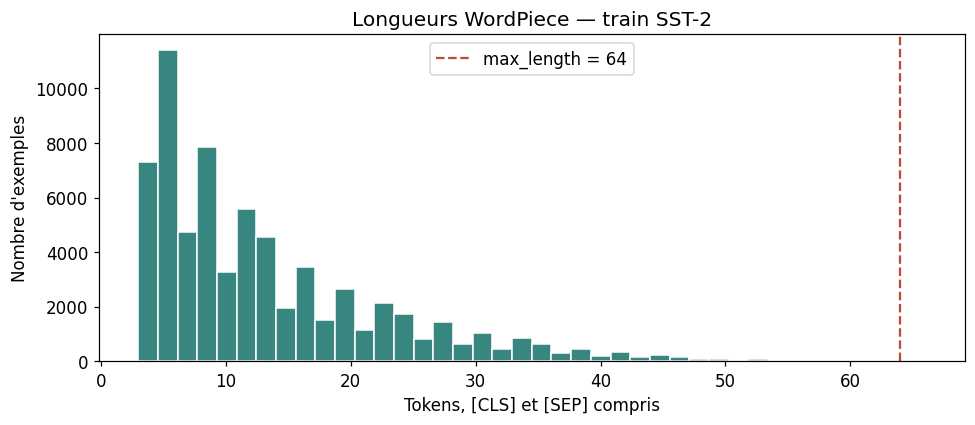

**Choix : `max_length=64`**, couvrant **99.99 %** du train sans troncature. Ce compromis limite la mémoire et le coût de l'attention. Il pourra tronquer des phrases de validation plus longues ; aucun score de validation n'a servi à le choisir.

In [26]:
bert_source = load_dataset("nyu-mll/glue", "sst2")
bert_raw = DatasetDict({name: bert_source[name] for name in ("train", "validation")})
assert len(bert_raw["train"]) == 67_349 and len(bert_raw["validation"]) == 872


def count_wordpieces(batch):
    encoded = bert_tokenizer(batch["sentence"], truncation=False, padding=False, return_length=True)
    return {"wordpiece_length": encoded["length"]}


wordpiece_lengths = bert_raw["train"].map(
    count_wordpieces, batched=True, batch_size=512,
    remove_columns=bert_raw["train"].column_names,
    desc="Longueurs WordPiece sur train uniquement",
)
train_wordpiece_lengths = np.asarray(wordpiece_lengths["wordpiece_length"])
display(pd.Series(train_wordpiece_lengths, name="WordPiece avec tokens spéciaux")
        .describe(percentiles=[0.5, 0.9, 0.95, 0.99]).to_frame().round(2))
length_coverage = pd.DataFrame([
    {"max_length": length, "couverture_train_pct": float(np.mean(train_wordpiece_lengths <= length) * 100),
     "textes_tronques": int(np.sum(train_wordpiece_lengths > length))}
    for length in (64, 128, 256, 512)
])
display(length_coverage)
MAX_LENGTH = next(int(row.max_length) for row in length_coverage.itertuples() if row.couverture_train_pct >= 99)
assert MAX_LENGTH <= bert_tokenizer.model_max_length

fig_wp, ax_wp = plt.subplots(figsize=(9, 4))
ax_wp.hist(train_wordpiece_lengths, bins=40, color="#378780", edgecolor="white")
ax_wp.axvline(MAX_LENGTH, color="#B94E38", linestyle="--", label=f"max_length = {MAX_LENGTH}")
ax_wp.set(title="Longueurs WordPiece — train SST-2", xlabel="Tokens, [CLS] et [SEP] compris", ylabel="Nombre d'exemples")
ax_wp.legend()
fig_wp.tight_layout()
plt.show()
chosen_coverage = float(np.mean(train_wordpiece_lengths <= MAX_LENGTH) * 100)
display(Markdown(
    f"**Choix : `max_length={MAX_LENGTH}`**, couvrant **{chosen_coverage:.2f} %** du train sans troncature. "
    "Ce compromis limite la mémoire et le coût de l'attention. Il pourra tronquer "
    "des phrases de validation plus longues ; aucun score de validation n'a servi à le choisir."
))


### 3.3 — Données alignées et padding dynamique

`bert_tokenized` conserve `idx` et `sentence` pour l'analyse et les futurs exports.
Le champ `label` devient `labels` sans changer ses valeurs. Une vue séparée
`bert_model_inputs` ne contient que les champs acceptés par le modèle.
`DataCollatorWithPadding` complète chaque lot à sa séquence la plus longue,
au lieu de compléter tout le corpus à `max_length`. Les deux vues gardent
strictement l'ordre et le nombre d'exemples du split officiel.


In [27]:
def tokenize_bert_batch(batch):
    """Tokeniser sans padding, conserver la troncature fixée à partir du train."""
    return bert_tokenizer(batch["sentence"], truncation=True, max_length=MAX_LENGTH, padding=False)


bert_tokenized = bert_raw.map(tokenize_bert_batch, batched=True, batch_size=512,
                              desc="Tokenisation BERT des splits officiels")
bert_tokenized = bert_tokenized.rename_column("label", "labels")
BERT_INPUT_COLUMNS = ["input_ids", "attention_mask", "token_type_ids", "labels"]
bert_model_inputs = DatasetDict({
    name: split.remove_columns([column for column in split.column_names if column not in BERT_INPUT_COLUMNS])
    for name, split in bert_tokenized.items()
})
bert_collator = DataCollatorWithPadding(tokenizer=bert_tokenizer, padding=True, return_tensors="pt")

for name in ("train", "validation"):
    aligned = bert_tokenized[name]
    assert len(aligned) == len(bert_raw[name])
    assert list(aligned["idx"]) == list(bert_raw[name]["idx"])
    assert list(aligned["sentence"]) == list(bert_raw[name]["sentence"])
    assert list(aligned["labels"]) == list(bert_raw[name]["label"])
    assert set(aligned["labels"]) == {0, 1}
    assert len(set(aligned["idx"])) == len(aligned)
    for row in bert_model_inputs[name]:
        length = len(row["input_ids"])
        assert 2 <= length <= MAX_LENGTH
        assert length == len(row["attention_mask"]) == len(row["token_type_ids"])
        assert row["attention_mask"] == [1] * length
        assert row["token_type_ids"] == [0] * length
        assert row["input_ids"][0] == bert_tokenizer.cls_token_id
        assert row["input_ids"][-1] == bert_tokenizer.sep_token_id

probe_features = [bert_model_inputs["train"][i] for i in range(4)]
bert_probe_batch = bert_collator(probe_features)
batch_shape = bert_probe_batch["input_ids"].shape
assert tuple(batch_shape) == (4, max(len(row["input_ids"]) for row in probe_features))
assert bert_probe_batch["attention_mask"].shape == batch_shape
assert bert_probe_batch["token_type_ids"].shape == batch_shape
assert bert_probe_batch["labels"].shape == (4,)
assert bert_probe_batch["labels"].dtype == torch.long
for index, feature in enumerate(probe_features):
    length = len(feature["input_ids"])
    assert bert_probe_batch["attention_mask"][index].sum().item() == length
    assert torch.all(bert_probe_batch["attention_mask"][index, length:] == 0)
    assert torch.all(bert_probe_batch["input_ids"][index, length:] == bert_tokenizer.pad_token_id)
print("Alignement idx/textes/labels et dimensions de tous les exemples : OK")
print("Lot dynamique :", {name: tuple(value.shape) for name, value in bert_probe_batch.items()})


Tokenisation BERT des splits officiels:   0%|          | 0/67349 [00:00<?, ? examples/s]

Tokenisation BERT des splits officiels:   0%|          | 0/872 [00:00<?, ? examples/s]

Alignement idx/textes/labels et dimensions de tous les exemples : OK
Lot dynamique : {'labels': (4,), 'input_ids': (4, 15), 'token_type_ids': (4, 15), 'attention_mask': (4, 15)}


### 3.4 — Encodeur préentraîné et tête de classification

`bert-base-uncased` possède 12 couches d'encodeur, des représentations de dimension
768 et 12 têtes d'attention par couche. Son préentraînement inclut le **MLM** :
reconstruire des mots masqués à partir des autres tokens. BERT a aussi utilisé
une tâche de prédiction de phrase suivante (NSP). Ce préentraînement ne lui fournit
pas directement un classifieur SST-2.

`AutoModelForSequenceClassification(..., num_labels=2)` réutilise l'encodeur et
ajoute une tête binaire. Pour BERT, la représentation finale de `[CLS]` passe par
le pooler, puis un dropout et la couche linéaire vers deux logits. Avec `labels`,
le modèle calcule une loss d'entropie croisée. Le fine-tuning supervisé modifiera
la tête **et l'encodeur**, à partir des labels du train.

L'avertissement de poids nouvellement initialisés pour `classifier.weight` et
`classifier.bias` est donc normal : cette tête n'a pas été entraînée pour SST-2.
Il faut vérifier les noms concernés ; un avertissement concernant de nombreuses
couches de l'encodeur ne doit pas être ignoré. Aucun score avant/après quelques
étapes ne constitue une performance finale.

Les poids sont téléchargés uniquement dans `.cache/bert/`, ignoré par Git. Avant
ce téléchargement, nous demandons au moins **3 Gio de RAM libre sur CPU**, ou
**2 Gio de RAM et 3 Gio de VRAM libres sur CUDA**. En cas d'insuffisance, le
notebook conserve les contrôles de tokenisation et indique les tests différés.


In [28]:
phase2_checks = {
    "api_signatures": "passed", "wordpiece_and_special_tokens": "passed",
    "train_length_distribution": "passed", "tokenized_alignment_and_masks": "passed",
    "dynamic_padding": "passed", "model_loading": "not_executed",
    "forward_and_loss": "not_executed", "trainer_backward_and_updates": "not_executed",
    "smoke_prediction_export": "not_executed",
}
smoke_status = "not_started"
smoke_reason = None
bert_model = None
smoke_trainer = None
smoke_metrics = None
smoke_predictions_path = None
gradient_check = None
phase2_memory_before_model = bert_memory_snapshot()
enough_memory = (
    phase2_memory_before_model["ram_available_gib"] >= (2.0 if HAS_CUDA else 3.0)
    and (not HAS_CUDA or phase2_memory_before_model["gpu_free_gib"] >= 3.0)
)

if enough_memory:
    try:
        set_seed(BERT_SEED)
        bert_model = AutoModelForSequenceClassification.from_pretrained(
            BERT_MODEL_NAME, num_labels=2,
            id2label={0: "negative", 1: "positive"}, label2id={"negative": 0, "positive": 1},
            cache_dir=str(PHASE2_CACHE / "bert"), use_safetensors=True,
        ).to(BERT_DEVICE)
        assert bert_model.config.model_type == "bert"
        assert bert_model.config.num_labels == 2
        assert bert_model.config.max_position_embeddings >= MAX_LENGTH
        assert bert_model.classifier.out_features == 2
        assert all(parameter.requires_grad for parameter in bert_model.parameters())
        phase2_checks["model_loading"] = "passed"
        print("Modèle chargé :", type(bert_model).__name__)
        print("Paramètres entraînables :", sum(p.numel() for p in bert_model.parameters() if p.requires_grad))
    except (RuntimeError, MemoryError) as exc:
        if not isinstance(exc, (torch.OutOfMemoryError, MemoryError)) and not any(
            text in str(exc).lower() for text in ("out of memory", "not enough memory", "can't allocate memory")
        ):
            raise
        bert_model = None
        gc.collect()
        if HAS_CUDA:
            torch.cuda.empty_cache()
        smoke_status = "deferred_memory"
        smoke_reason = f"Mémoire insuffisante pendant le chargement : {type(exc).__name__}"
else:
    smoke_status = "deferred_memory"
    smoke_reason = "RAM/VRAM libre sous le seuil de précaution ; poids non téléchargés et smoke test différé."

print("Mémoire avant chargement :", phase2_memory_before_model)
if bert_model is None:
    print("TESTS MODÈLE NON EXÉCUTÉS :", smoke_reason)
    print("Sur Colab : choisir un GPU, redémarrer la session si nécessaire, puis reprendre en section 3.")


model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Modèle chargé : BertForSequenceClassification
Paramètres entraînables : 109483778
Mémoire avant chargement : {'ram_available_gib': 8.826515197753906, 'process_rss_gib': 1.3851394653320312, 'gpu_free_gib': 14.46075439453125, 'gpu_total_gib': 14.56317138671875, 'gpu_allocated_gib': 0.0, 'gpu_reserved_gib': 0.0, 'gpu_peak_allocated_gib': 0.0}


### 3.5 — Trainer : configuration prévue et smoke test borné

Le dictionnaire `PHASE3_PLAN` décrit uniquement la future expérience : **2 époques,
learning rate `2e-5`, seed 42**, batch 16 sur GPU (2 sur CPU à adapter), accuracy et
F1 de la classe positive 1. **Il ne lance aucun entraînement.** La taille effective
du batch pourra être ajustée en phase 3 selon la mémoire disponible.

Le seul `Trainer` exécuté ici reçoit **16 exemples de train** et **8 exemples de
validation**, choisis avec la seed 42 et sans mélange des splits. `max_steps=2`
limite le nombre de mises à jour, avec batch 2 sur GPU ou 1 sur CPU. Le smoke test
utilise du float32 et un learning rate constant pour faciliter les contrôles.
Un callback vérifie des gradients finis et non nuls dans la tête et l'encodeur
avant l'optimiseur ; les poids sont comparés avant/après les deux mises à jour.

Aucun checkpoint n'est sauvegardé, aucun envoi vers le Hub ni service de suivi
externe n'est activé. Les éventuels scores sont marqués **smoke uniquement**.
Après ce test, le modèle est modifié : **la phase 3 devra recharger le modèle
préentraîné avec la seed 42**, sans repartir de ces poids techniques.


In [29]:
PHASE3_PLAN = {
    "model": BERT_MODEL_NAME, "num_train_epochs": 2, "learning_rate": 2e-5,
    "seed": BERT_SEED, "per_device_train_batch_size": 16 if HAS_CUDA else 2,
    "per_device_eval_batch_size": 32 if HAS_CUDA else 2,
    "max_length": MAX_LENGTH, "metrics": ["accuracy", "f1_positive"],
    "positive_label": 1, "device": str(BERT_DEVICE),
    "status": "planned_only_requires_phase3_approval",
}
SMOKE_TRAIN_SIZE = 16
SMOKE_VALIDATION_SIZE = 8
SMOKE_MAX_STEPS = 2
smoke_train_indices = bert_raw["train"].shuffle(seed=BERT_SEED).select(range(SMOKE_TRAIN_SIZE))["idx"]
smoke_validation_indices = bert_raw["validation"].shuffle(seed=BERT_SEED).select(range(SMOKE_VALIDATION_SIZE))["idx"]

# Les indices idx de SST-2 correspondent ici aux positions, ce qui est vérifié.
assert list(bert_raw["train"]["idx"]) == list(range(len(bert_raw["train"])))
assert list(bert_raw["validation"]["idx"]) == list(range(len(bert_raw["validation"])))
smoke_train_inputs = bert_model_inputs["train"].select(smoke_train_indices)
smoke_validation_inputs = bert_model_inputs["validation"].select(smoke_validation_indices)
smoke_validation_source = bert_raw["validation"].select(smoke_validation_indices)
assert len(smoke_train_inputs) == 16 and len(smoke_validation_inputs) == 8


def compute_bert_metrics(evaluation):
    logits = evaluation.predictions[0] if isinstance(evaluation.predictions, tuple) else evaluation.predictions
    predictions = np.argmax(logits, axis=-1)
    return {
        "accuracy": float(accuracy_score(evaluation.label_ids, predictions)),
        "f1_positive": float(f1_score(evaluation.label_ids, predictions, pos_label=1, zero_division=0)),
    }


class BertGradientCheck(TrainerCallback):
    """Vérifier la rétropropagation avant que l'optimiseur n'efface les gradients."""
    def __init__(self):
        self.checked_steps = 0
        self.completed_steps = 0

    def on_pre_optimizer_step(self, args, state, control, model=None, **kwargs):
        for parameter in (model.classifier.weight, model.bert.encoder.layer[0].attention.output.dense.bias):
            gradient = parameter.grad
            if gradient is None or not torch.isfinite(gradient).all() or not torch.any(gradient != 0):
                raise RuntimeError("Gradient absent, non fini ou nul dans la tête ou l'encodeur.")
        self.checked_steps += 1

    def on_step_end(self, args, state, control, **kwargs):
        self.completed_steps = state.global_step


smoke_args = TrainingArguments(
    output_dir=str(PHASE2_CACHE / "bert-smoke"), max_steps=SMOKE_MAX_STEPS,
    per_device_train_batch_size=2 if HAS_CUDA else 1,
    per_device_eval_batch_size=2 if HAS_CUDA else 1,
    gradient_accumulation_steps=1, learning_rate=2e-5, lr_scheduler_type="constant",
    seed=BERT_SEED, data_seed=BERT_SEED, use_cpu=not HAS_CUDA,
    fp16=False, bf16=False, optim="adamw_torch",
    eval_strategy="no", save_strategy="no", logging_strategy="steps", logging_steps=1,
    report_to="none", push_to_hub=False, disable_tqdm=True,
    dataloader_num_workers=0, dataloader_pin_memory=HAS_CUDA,
)
assert smoke_args.max_steps == 2 and smoke_args.gradient_accumulation_steps == 1
print("Plan phase 3, sans exécution :", PHASE3_PLAN)
print("Smoke test :", len(smoke_train_inputs), "exemples train,", len(smoke_validation_inputs),
      "exemples validation,", smoke_args.max_steps, "étapes maximum.")


Plan phase 3, sans exécution : {'model': 'bert-base-uncased', 'num_train_epochs': 2, 'learning_rate': 2e-05, 'seed': 42, 'per_device_train_batch_size': 16, 'per_device_eval_batch_size': 32, 'max_length': 64, 'metrics': ['accuracy', 'f1_positive'], 'positive_label': 1, 'device': 'cuda', 'status': 'planned_only_requires_phase3_approval'}
Smoke test : 16 exemples train, 8 exemples validation, 2 étapes maximum.


### Prédictions individuelles et futures comparaisons appariées

L'export conserve **`split`, `idx`, `sentence`, `true_label`, `predicted_label`**,
ainsi que les deux logits et la probabilité positive. `run_kind="smoke"` identifie
explicitement le test technique. Les huit lignes sont exportées sous
`results/phase2/bert_smoke_predictions.csv` seulement après un test réussi.

Pour la future expérience complète, conserver les **872 prédictions** dans
`results/bert_predictions.csv`, avec le même schéma et l'indication d'une expérience
complète. L'appariement avec TF-IDF devra se faire par `(split, idx)` — les `idx`
sont propres à chaque split — puis vérifier l'égalité des textes et labels.
Cela permettra de compter les désaccords et, si retenu, de construire la table de
McNemar sur les erreurs appariées. Aucun test statistique ni comparaison de scores
n'est réalisé dans cette phase ; les huit prédictions techniques n'y conviennent pas.


In [30]:
def export_bert_predictions(prediction_output, source_split, destination, *, run_kind):
    """Exporter dans l'ordre de source_split, sans perdre l'alignement individuel."""
    logits = prediction_output.predictions
    if isinstance(logits, tuple):
        logits = logits[0]
    logits = np.asarray(logits)
    labels = np.asarray(source_split["label"], dtype=np.int64)
    if labels.ndim != 1 or not np.isin(labels, [0, 1]).all():
        raise ValueError("Les labels source doivent être binaires.")
    if logits.shape != (len(source_split), 2) or not np.isfinite(logits).all():
        raise ValueError("Logits non finis ou dimensions incompatibles avec les exemples.")
    if not np.array_equal(prediction_output.label_ids, labels):
        raise ValueError("Les labels de Trainer ne sont pas alignés avec le split source.")
    if not run_kind or len(set(source_split["idx"])) != len(source_split):
        raise ValueError("Type d'expérience requis et idx uniques dans le split nécessaires.")
    shifted = logits - logits.max(axis=1, keepdims=True)
    probabilities = np.exp(shifted) / np.exp(shifted).sum(axis=1, keepdims=True)
    table = pd.DataFrame({
        "split": "validation", "idx": list(source_split["idx"]),
        "sentence": list(source_split["sentence"]), "true_label": labels,
        "predicted_label": logits.argmax(axis=1), "probability_positive": probabilities[:, 1],
        "logit_0": logits[:, 0], "logit_1": logits[:, 1], "run_kind": run_kind,
        "model_name": BERT_MODEL_NAME, "max_length": MAX_LENGTH, "seed": BERT_SEED,
    })
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)
    table.to_csv(destination, index=False, encoding="utf-8")
    reloaded = pd.read_csv(destination, keep_default_na=False)
    assert reloaded["idx"].tolist() == list(source_split["idx"])
    assert reloaded["sentence"].tolist() == list(source_split["sentence"])
    assert reloaded["true_label"].tolist() == labels.tolist()
    assert reloaded["predicted_label"].tolist() == logits.argmax(axis=1).tolist()
    assert reloaded["probability_positive"].between(0, 1).all()
    return table


if bert_model is not None:
    try:
        if HAS_CUDA:
            torch.cuda.reset_peak_memory_stats()
        bert_model.eval()
        forward_batch = bert_collator([smoke_train_inputs[i] for i in range(2)])
        forward_batch = {name: value.to(BERT_DEVICE) for name, value in forward_batch.items()}
        with torch.no_grad():
            forward_output = bert_model(**forward_batch)
        assert forward_output.logits.shape == (2, 2)
        assert forward_output.loss.ndim == 0 and torch.isfinite(forward_output.loss)
        print("Passage avant : logits (2, 2), loss scalaire finie ; valeur technique :", forward_output.loss.item())
        phase2_checks["forward_and_loss"] = "passed"
        del forward_batch, forward_output

        head_before = bert_model.classifier.weight.detach().cpu().clone()
        encoder_before = bert_model.bert.encoder.layer[0].attention.output.dense.bias.detach().cpu().clone()
        gradient_check = BertGradientCheck()
        smoke_trainer = Trainer(
            model=bert_model, args=smoke_args, train_dataset=smoke_train_inputs,
            eval_dataset=smoke_validation_inputs, data_collator=bert_collator,
            processing_class=bert_tokenizer, compute_metrics=compute_bert_metrics,
            callbacks=[gradient_check],
        )
        assert len(smoke_trainer.train_dataset) == 16
        smoke_train_result = smoke_trainer.train()
        assert smoke_trainer.state.global_step == SMOKE_MAX_STEPS
        assert gradient_check.checked_steps == SMOKE_MAX_STEPS
        assert np.isfinite(smoke_train_result.training_loss)
        assert not torch.equal(head_before, bert_model.classifier.weight.detach().cpu())
        assert not torch.equal(encoder_before, bert_model.bert.encoder.layer[0].attention.output.dense.bias.detach().cpu())
        phase2_checks["trainer_backward_and_updates"] = "passed"

        smoke_output = smoke_trainer.predict(smoke_validation_inputs, metric_key_prefix="smoke_only")
        smoke_metrics = {key: float(value) for key, value in smoke_output.metrics.items()}
        smoke_predictions_path = PHASE2_RESULTS / "bert_smoke_predictions.csv"
        smoke_predictions_table = export_bert_predictions(
            smoke_output, smoke_validation_source, smoke_predictions_path, run_kind="smoke"
        )
        phase2_checks["smoke_prediction_export"] = "passed"
        smoke_status = "passed_technical_only"
        print("SMOKE TEST TECHNIQUE RÉUSSI ; aucun score final BERT.")
        print("Métriques du sous-échantillon, non comparables à TF-IDF :", smoke_metrics)
        display(smoke_predictions_table[["idx", "true_label", "predicted_label", "run_kind"]])
    except (RuntimeError, MemoryError) as exc:
        if not isinstance(exc, (torch.OutOfMemoryError, MemoryError)) and not any(
            text in str(exc).lower() for text in ("out of memory", "not enough memory", "can't allocate memory")
        ):
            raise
        smoke_status = "deferred_memory"
        smoke_reason = f"Dépassement mémoire pendant le smoke test : {type(exc).__name__}"
        smoke_metrics = None
        smoke_predictions_path = None
        print(smoke_reason)
        print("Reprendre dans une session Colab avec davantage de mémoire ; recharger BERT avant de relancer.")
        smoke_trainer = None
        bert_model = None
        gc.collect()
        if HAS_CUDA:
            torch.cuda.empty_cache()
else:
    print("Passage avant, loss, rétropropagation, Trainer et prédictions : NON EXÉCUTÉS.")
    print("Motif :", smoke_reason)


Passage avant : logits (2, 2), loss scalaire finie ; valeur technique : 0.6341825723648071
{'loss': 0.5948, 'grad_norm': 12.868246078491211, 'learning_rate': 2e-05, 'epoch': 0.125}
{'loss': 0.5398, 'grad_norm': 12.5709810256958, 'learning_rate': 2e-05, 'epoch': 0.25}
{'train_runtime': 0.7352, 'train_samples_per_second': 5.441, 'train_steps_per_second': 2.72, 'train_loss': 0.5672794282436371, 'epoch': 0.25}
SMOKE TEST TECHNIQUE RÉUSSI ; aucun score final BERT.
Métriques du sous-échantillon, non comparables à TF-IDF : {'smoke_only_loss': 0.6355546712875366, 'smoke_only_accuracy': 0.75, 'smoke_only_f1_positive': 0.8571428571428571, 'smoke_only_runtime': 0.0874, 'smoke_only_samples_per_second': 91.558, 'smoke_only_steps_per_second': 45.779}


,idx,true_label,predicted_label,run_kind
0,726,1,1,smoke
1,737,1,1,smoke
2,51,1,1,smoke
3,482,1,1,smoke
4,426,1,1,smoke
5,330,0,1,smoke
6,243,1,1,smoke
7,7,0,1,smoke


### 3.6 — Bilan technique et arrêt obligatoire

Le rapport ci-dessous enregistre uniquement ce qui a réellement été contrôlé,
les versions, le choix de longueur, les ressources et le statut du smoke test.
Les contrôles différés sont marqués `not_executed`, sans métriques fictives.
Les empreintes des trois résultats TF-IDF sont vérifiées à la fin si ces fichiers
étaient présents au début. L'ouverture du notebook seul dans Colab ne les requiert pas.

Pour valider la phase 2 dans Colab, télécharger le notebook avec ses nouvelles
sorties, `results/phase2/bert_technical_report.json`, et, **s'il a été produit après
succès**, `results/phase2/bert_smoke_predictions.csv`. Les poids du modèle restent
dans le cache et ne doivent pas être versionnés.

**Arrêt après ces contrôles.** La phase 3 nécessite une validation explicite,
un smoke test réussi sur la machine retenue et le rechargement du modèle initial.
Les deux époques sur 67 349 exemples, les 872 prédictions finales, la comparaison
et un éventuel test de McNemar ne sont pas exécutés ici. Aucun commit ni push.


In [31]:
for baseline_path in BASELINE_FILES:
    if baseline_path.name in baseline_hashes_before:
        assert hashlib.sha256(baseline_path.read_bytes()).hexdigest() == baseline_hashes_before[baseline_path.name]
phase2_checks["baseline_files_unchanged"] = "passed" if baseline_hashes_before else "not_present_in_this_session"
technical_report = {
    "phase": 2, "run_kind": "technical_smoke_only", "model_name": BERT_MODEL_NAME,
    "completed_at_utc": datetime.now(timezone.utc).isoformat(),
    "reference_commit": "ecb4c82e3a36fd1c3d3d05b2efaad01e996feb5a",
    "status": smoke_status, "reason": smoke_reason, "checks": phase2_checks,
    "versions": PHASE2_VERSIONS, "python": platform.python_version(),
    "device": str(BERT_DEVICE), "gpu_name": torch.cuda.get_device_name(0) if HAS_CUDA else None,
    "max_length": MAX_LENGTH, "train_coverage_percent": chosen_coverage,
    "train_wordpiece_percentiles": {str(p): float(np.percentile(train_wordpiece_lengths, p)) for p in (50, 90, 95, 99)},
    "train_wordpiece_max": int(train_wordpiece_lengths.max()),
    "smoke_train_size": SMOKE_TRAIN_SIZE, "smoke_validation_size": SMOKE_VALIDATION_SIZE,
    "smoke_max_steps": SMOKE_MAX_STEPS,
    "optimizer_steps_executed": int(gradient_check.completed_steps) if gradient_check is not None else 0,
    "smoke_only_metrics": smoke_metrics,
    "smoke_predictions_file": smoke_predictions_path.relative_to(PHASE2_ROOT).as_posix() if smoke_predictions_path else None,
    "memory_initial": phase2_memory_initial, "memory_before_model": phase2_memory_before_model,
    "memory_after": bert_memory_snapshot(),
    "baseline_hashes_unchanged": baseline_hashes_before,
    "phase3_plan_not_executed": PHASE3_PLAN,
    "dataset_fingerprints": {name: bert_raw[name]._fingerprint for name in ("train", "validation")},
}
report_path = PHASE2_RESULTS / "bert_technical_report.json"
report_path.write_text(json.dumps(technical_report, ensure_ascii=False, indent=2, allow_nan=False) + "\n", encoding="utf-8")
display(pd.Series(phase2_checks, name="statut").to_frame())
print("Rapport :", report_path.name, "| statut :", smoke_status)
print("FIN DE PHASE 2 : attendre la validation avant l'entraînement complet.")


,statut
api_signatures,passed
wordpiece_and_special_tokens,passed
train_length_distribution,passed
tokenized_alignment_and_masks,passed
dynamic_padding,passed
model_loading,passed
forward_and_loss,passed
trainer_backward_and_updates,passed
smoke_prediction_export,passed
baseline_files_unchanged,passed


Rapport : bert_technical_report.json | statut : passed_technical_only
FIN DE PHASE 2 : attendre la validation avant l'entraînement complet.


### Références de la phase 2

- [Fiche de BERT base uncased](https://huggingface.co/google-bert/bert-base-uncased).
- [Classification de textes et padding dynamique](https://huggingface.co/docs/transformers/v4.57.1/en/tasks/sequence_classification).
- [API Trainer et TrainingArguments](https://huggingface.co/docs/transformers/v4.57.1/en/main_classes/trainer).
Les signatures sont contrôlées dans les versions effectivement installées.
